In [ ]:
# Step 10: Smart Analytics Dashboard

## Objective
# Develop a Python-based analytics dashboard to monitor chatbot
# performance, user interactions and conversation trends.

# ## Key Features
# 1. Total chatbot interactions.
# 2. Intent distribution.
# 3. Fallback and confidence analysis.
# 4. User feedback analysis.
# 5. Sentiment distribution.
# 6. Conversation trends.
# 7. Visual analytics and performance reports.

# ## Tools
# - Python
# - Pandas
# - Matplotlib
# - Jupyter Notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Dashboard libraries imported successfully.")

Dashboard libraries imported successfully.


In [2]:
# Set project paths

PROJECT_ROOT = Path(r"D:\Dynamic_AI_Chatbot_Project")

INTERACTION_PATH = (
    PROJECT_ROOT / "outputs" / "self_learning" /
    "interaction_history.csv"
)

FEEDBACK_PATH = (
    PROJECT_ROOT / "outputs" / "self_learning" /
    "user_feedback.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "analytics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project paths configured successfully.")

Project paths configured successfully.


In [3]:
# Load interaction and feedback data

if not INTERACTION_PATH.exists():
    raise FileNotFoundError(
        f"Interaction history not found: {INTERACTION_PATH}"
    )

if not FEEDBACK_PATH.exists():
    raise FileNotFoundError(
        f"Feedback file not found: {FEEDBACK_PATH}"
    )

interactions_df = pd.read_csv(INTERACTION_PATH)
feedback_df = pd.read_csv(FEEDBACK_PATH)

print("Interaction records:", len(interactions_df))
print("Feedback records:", len(feedback_df))

display(interactions_df.head())
display(feedback_df.head())

Interaction records: 3
Feedback records: 1


,timestamp,user_message,predicted_intent,confidence,chatbot_response,user_feedback
0,2026-11-22 19:40:11,"Hello, I need some help.",fallback,0.246408,I'm not completely sure I understood your requ...,Not provided
1,2026-11-22 19:40:11,I want to speak with a human representative.,fallback,0.290128,I'm not completely sure I understood your requ...,Not provided
2,2026-11-22 19:40:11,Thank you for your support.,fallback,0.230534,I'm not completely sure I understood your requ...,Not provided


,timestamp,user_message,predicted_intent,confidence,user_feedback,corrected_intent
0,2026-11-22 19:38:40,I need help with my internet connection.,request_support,0.82,Incorrect,complaint


In [4]:
# Generate KPI summary

total_interactions = len(interactions_df)

fallback_count = (
    interactions_df["predicted_intent"]
    .astype(str)
    .str.lower()
    .eq("fallback")
    .sum()
)

fallback_rate = (
    fallback_count / total_interactions * 100
    if total_interactions > 0 else 0
)

average_confidence = (
    pd.to_numeric(
        interactions_df["confidence"],
        errors="coerce"
    ).mean()
)

total_feedback = len(feedback_df)

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Interactions",
        "Fallback Interactions",
        "Fallback Rate (%)",
        "Average Intent Confidence",
        "Total Feedback Records"
    ],
    "Value": [
        total_interactions,
        fallback_count,
        round(fallback_rate, 2),
        round(average_confidence, 3),
        total_feedback
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Interactions,3.000
1,Fallback Interactions,3.000
2,Fallback Rate (%),100.000
3,Average Intent Confidence,0.256
4,Total Feedback Records,1.000


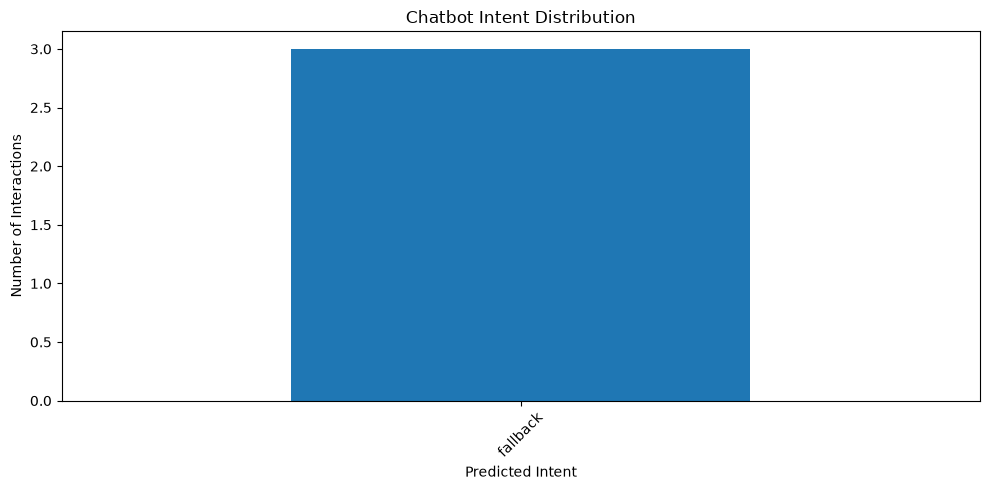

In [6]:
# Intent distribution chart

intent_counts = interactions_df["predicted_intent"].value_counts()

plt.figure(figsize=(10, 5))
intent_counts.plot(kind="bar")

plt.title("Chatbot Intent Distribution")
plt.xlabel("Predicted Intent")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "intent_distribution.png")
plt.show()

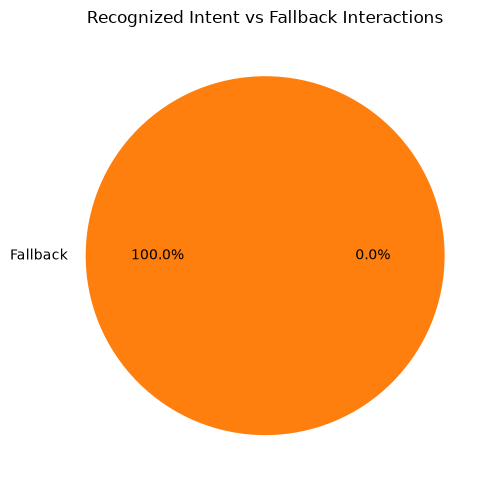

In [5]:
# Fallback analysis

fallback_summary = pd.Series({
    "Recognized Intent": total_interactions - fallback_count,
    "Fallback": fallback_count
})

plt.figure(figsize=(7, 5))
fallback_summary.plot(kind="pie", autopct="%1.1f%%")

plt.title("Recognized Intent vs Fallback Interactions")
plt.ylabel("")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fallback_analysis.png")
plt.show()

user_feedback
Incorrect    1
Name: count, dtype: int64

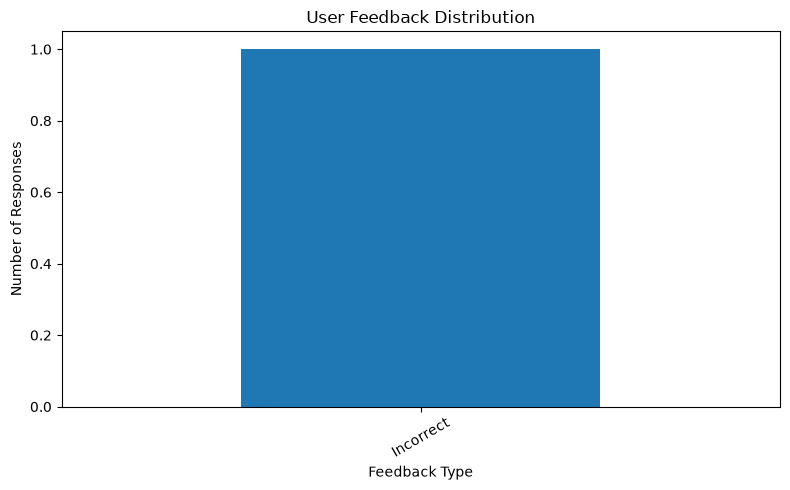

In [7]:
# Feedback distribution

feedback_counts = feedback_df["user_feedback"].value_counts()

display(feedback_counts)

plt.figure(figsize=(8, 5))
feedback_counts.plot(kind="bar")

plt.title("User Feedback Distribution")
plt.xlabel("Feedback Type")
plt.ylabel("Number of Responses")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "user_feedback_analysis.png")
plt.show()

Date
2026-11-22    3
dtype: int64

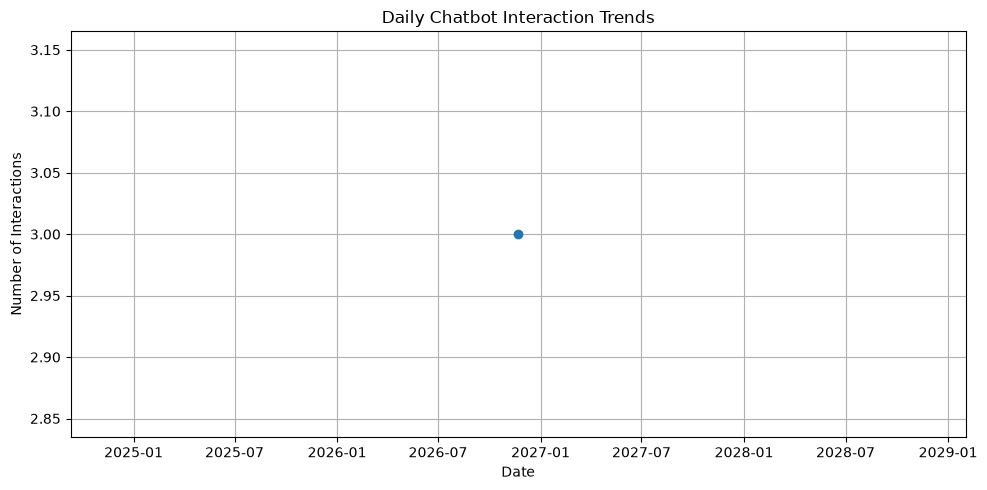

In [8]:
# Daily interaction trends

interactions_df["timestamp"] = pd.to_datetime(
    interactions_df["timestamp"],
    errors="coerce"
)

daily_interactions = (
    interactions_df.dropna(subset=["timestamp"])
    .assign(Date=lambda df: df["timestamp"].dt.date)
    .groupby("Date")
    .size()
)

display(daily_interactions)

plt.figure(figsize=(10, 5))
daily_interactions.plot(kind="line", marker="o")

plt.title("Daily Chatbot Interaction Trends")
plt.xlabel("Date")
plt.ylabel("Number of Interactions")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "daily_interaction_trends.png")
plt.show()

In [9]:
# Save KPI report

kpi_path = OUTPUT_DIR / "chatbot_kpi_summary.csv"

kpi_summary.to_csv(kpi_path, index=False)

print("Analytics KPI report saved successfully.")
print("Location:", kpi_path)

Analytics KPI report saved successfully.
Location: D:\Dynamic_AI_Chatbot_Project\outputs\analytics\chatbot_kpi_summary.csv


In [10]:
# Verify dashboard outputs

print("DASHBOARD OUTPUT VERIFICATION")
print("-" * 50)

for file_path in sorted(OUTPUT_DIR.iterdir()):
    if file_path.is_file():
        print(file_path.name, "|", file_path.stat().st_size, "bytes")

print("-" * 50)
print("Dashboard output verification completed.")

DASHBOARD OUTPUT VERIFICATION
--------------------------------------------------
chatbot_kpi_summary.csv | 151 bytes
daily_interaction_trends.png | 23298 bytes
fallback_analysis.png | 15682 bytes
intent_distribution.png | 15526 bytes
user_feedback_analysis.png | 16025 bytes
--------------------------------------------------
Dashboard output verification completed.
